In [1]:
import os
import pandas as pd
import scanpy as sc
import networkx as nx
import matplotlib.pyplot as plt

In [2]:
pth = os.path.join('..', '..', '..')
pth_data = os.path.join(pth, 'data')
pth_in = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
pth_res = os.path.join(pth_data, 'results', 'therapeutic', 'vaccines')
pth_safe = os.path.join(pth_res, 'safety')
pth_fig = os.path.join(pth, 'figures', 'therapeutic', 'vaccines')

In [3]:
# load safety thresholds
fn = os.path.join(pth_safe, 'single.csv')
df_single = pd.read_csv(fn, index_col = 0)
fn = os.path.join(pth_safe, 'pair.csv')
df_pair = pd.read_csv(fn, index_col = [0, 1])

In [4]:
# load features (pSom)
fn = os.path.join(pth_feat, 'GSE229103.csv')
g = pd.read_csv(fn).hsapiens.drop_duplicates()
g = g.loc[g.isin(df_single.index)].copy()

In [5]:
# load 3CA malignant cells
fn = os.path.join(pth_in, 'malignant.h5ad')
adata = sc.read_h5ad(fn)
adata.obs = adata.obs.join(pd.DataFrame(
        data = adata[:, g].X.toarray(),
        index = adata.obs_names, columns = g))
adata

AnnData object with n_obs × n_vars = 1406087 × 245
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'ebv', 'celltype', 'Title', 'Category', 'Disease', 'Technology', 'Samples', 'Cells', 'Name', 'patient', 'cell_subtype', 'source', 'disease', 'p16_status', 'site', 't_stage', 'n_stage', 'gender', 'race', 'age', 'tobacco_use', 'alcohol_use', 'hpv', 'hpv_score', 'treatment', 'procedure', 'sorting', 'cluster', 'malignant', 'sample_id', 'cell_subtype_clusters', 'tnm_stage', 'viral', 'location', 'cancer_type', 'treatment_exposure', 'treatment_response', 'cell_lineage', 'type', 'clusters_by_authors', 'cell_QCpass', 'is_tumor', 'cell_compartment', 'cluster_assignment', 'metastasis', 'sex', 'prior_enzalutamide', 'prior_abiraterone', 'prior_taxane', 'prior_platinum', 'prior_sipuleucel_T', 'purity', 'has_bulk_RNA', 'cancer_cell_state', 'PSA', 'source_region', 'gleason_score', 'ERG_status', 'cores

In [6]:
# groupby: sample x source x disease
by = ['sample', 'source', 'Disease']
grp = (adata.obs
       .groupby(by, observed = True)
       .filter(lambda sdf: len(sdf) > 50)
       .groupby(by, observed = True))

In [7]:
# mean intra-tumor coexpression (spearman)
keys = grp.groups.keys()
ix = pd.MultiIndex.from_tuples(keys, names = by)
msk_col = df_pair.index.to_frame().isin(g.values)
col = df_pair.index[msk_col.all(axis = 1)]
df_corr = pd.DataFrame(index = ix, columns = col)
for name, sdf in grp:
    R = sdf[g].corr('spearman')
    df_corr.loc[name] = R.unstack().loc[col]
df_corr = (df_corr.mean().rename('Correlation')
           .sort_values(ascending = False))

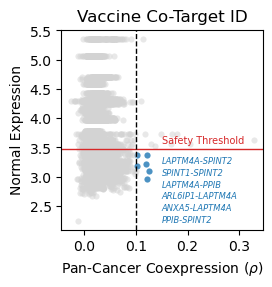

In [8]:
# coexpression (cancer) vs. expression (normal)
thresh_expr = df_single.loc['GPC3'].Expression.copy()
df_expr = df_pair.loc[df_corr.index].Expression.copy()
df_plt = pd.concat((df_corr, df_expr), axis = 1)
df_plt.to_csv(os.path.join(pth_res, 'discovery.csv'))

thresh_corr = .1
msk_expr = (df_expr < thresh_expr)
msk_corr = (df_corr > thresh_corr)
msk_tgt = (msk_expr & msk_corr)

# plot scatter
fig, ax = plt.subplots(1, 1, figsize = (2.6, 2.6))
ax.scatter(df_plt.loc[msk_tgt].Correlation,
           df_plt.loc[msk_tgt].Expression,
           linewidth = 0, alpha = .8, s = 20,
           c = 'tab:blue')
ax.scatter(df_plt.loc[~msk_tgt].Correlation,
           df_plt.loc[~msk_tgt].Expression,
           linewidth = 0, alpha = .5, s = 20,
           c = 'lightgray')

# thresholds: correlation, expression
ax.axhline(thresh_expr, c = 'tab:red', lw = 1)
ax.axvline(thresh_corr, c = 'k', ls = '--', lw = 1)
ax.text(.15, thresh_expr + .1, 'Safety Threshold',
        fontsize = 7, c = 'tab:red')

# co-target labels
for i, gpair in enumerate(df_plt.index[msk_tgt]):
    ax.text(x = .15, y = 3.225 - (.2 * i),
            s = '-'.join(list(gpair)),
            fontstyle = 'italic', c = 'tab:blue',
            fontsize = 6)

ax.set_xlabel(r'Pan-Cancer Coexpression ($\rho$)')
ax.set_ylabel('Normal Expression')
ax.set_title('Vaccine Co-Target ID')
fn = os.path.join(pth_fig, 'discovery.pdf')
plt.savefig(fn, bbox_inches = 'tight')

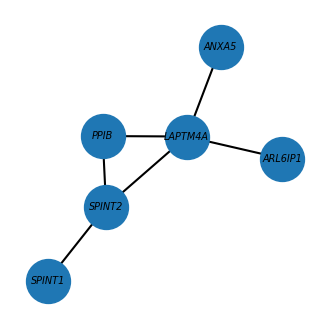

In [9]:
# construct co-target graph
edges = df_plt.index[msk_tgt].values
G_tgt = nx.from_edgelist(edges,
        create_using = nx.Graph)

# plot coexpression network
fig, ax = plt.subplots(1, 1, figsize = (4, 4))
pos = nx.spring_layout(G_tgt, seed = 1)
nx.draw_networkx_nodes(
    G_tgt, pos, ax = ax,
    node_color = 'tab:blue',
    node_size = 1000)
lbl = nx.draw_networkx_labels(
    G_tgt, pos, ax = ax,
    font_size = 7)
for t in lbl.values():
    t.set_fontstyle('italic')
nx.draw_networkx_edges(
    G_tgt, pos, ax = ax,
    width = 1.5)
ax.axis('off'); ax.margins(.1)
fn = os.path.join(pth_fig, 'network.pdf')
plt.savefig(fn, bbox_inches = 'tight')